# Bài 5 — Pure Monte Carlo Search

Thực hiện: Ly. Công cụ hỗ trợ: OpenAI Codex (code và kiểm thử). Người nộp cần tự đọc và xác nhận kết quả.

## Quy tắc và bộ trạng thái chung

Import API đóng băng từ `tictactoe.py`. T1–T4 trùng protocol nhóm; X là người được đánh giá trên bộ trạng thái. T3 được giữ nguyên từ đề dù số quân không mô tả lượt X trong một ván bắt đầu bằng X; đây là fixture search, không dùng để khởi đầu thi đấu.

In [1]:
from pathlib import Path
from time import perf_counter
from collections import Counter
from functools import lru_cache
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tictactoe import empty_board, actions, result, utility, other
SEED = 42
REPEATS = 30
GAMES_PER_ROLE = 100
DEBUG = 0

# Cache only deterministic rules; every simulated trajectory is still random.
@lru_cache(None)
def cached_utility(state, player):
    return utility(list(state), player)

@lru_cache(None)
def legal_actions(state):
    return tuple(actions(list(state)))

def playout(board, action, player='x', rng=None):
    rng = np.random.default_rng() if rng is None else rng
    state = tuple(result(list(board), player, action))
    current = other(player)
    while True:
        value = cached_utility(state, player)
        if value is not None:
            return value
        move = int(rng.choice(legal_actions(state)))
        state = tuple(result(list(state), current, move))
        current = other(current)

@lru_cache(None)
def exact_value(state, player):
    value = cached_utility(state, player)
    if value is not None:
        return value
    return max(-exact_value(tuple(result(list(state), player, a)), other(player))
               for a in legal_actions(state))

def optimal_moves(board, player='x'):
    values = {a: -exact_value(tuple(result(list(board), player, a)), other(player))
              for a in legal_actions(tuple(board))}
    best = max(values.values())
    return best, {a for a, value in values.items() if value == best}

STATES = {
    'T1 X sap thang': ['x','o',' ','o','x',' ',' ',' ',' '],
    'T2 X can hoa': ['x','o','x',' ','o',' ',' ',' ',' '],
    'T3 bat loi': ['o',' ','x',' ',' ',' ',' ',' ','o'],
    'T4 ban rong': empty_board(),
}
display(pd.DataFrame([{'state': label, 'board': ''.join(c if c != ' ' else '.' for c in b),
                       'optimal_value': optimal_moves(b)[0],
                       'optimal_moves': sorted(optimal_moves(b)[1])}
                      for label, b in STATES.items()]))
print({'seed': SEED, 'repeats': REPEATS, 'games_per_role': GAMES_PER_ROLE,
       'Python': platform.python_version(), 'NumPy': np.__version__})

def markdown_table(frame):
    headers = [str(c) for c in frame.columns]
    rows = ['|' + '|'.join(headers) + '|', '|' + '|'.join(['---'] * len(headers)) + '|']
    for row in frame.itertuples(index=False, name=None):
        rows.append('|' + '|'.join(f'{v:.6f}' if isinstance(v, float) else str(v) for v in row) + '|')
    return '\n'.join(rows)

def record_section(key, text):
    path = Path('results/ly_results.md')
    path.parent.mkdir(exist_ok=True)
    old = path.read_text(encoding='utf-8') if path.exists() else '# Kết quả cá nhân — Ly\n\n'
    begin, end = f'<!-- BEGIN {key} -->', f'<!-- END {key} -->'
    block = begin + '\n' + text + '\n' + end
    if begin in old:
        start = old.index(begin)
        stop = old.index(end, start) + len(end)
        old = old[:start] + block + old[stop:]
    else:
        old += '\n' + block + '\n'
    path.write_text(old, encoding='utf-8')

,state,board,optimal_value,optimal_moves
0,T1 X sap thang,xo.ox....,1,"[2, 6, 8]"
1,T2 X can hoa,xox.o....,0,[7]
2,T3 bat loi,o.x.....o,-1,"[1, 3, 4, 5, 6, 7]"
3,T4 ban rong,.........,0,"[0, 1, 2, 3, 4, 5, 6, 7, 8]"


{'seed': 42, 'repeats': 30, 'games_per_role': 100, 'Python': '3.13.5', 'NumPy': '2.3.4'}


## Thuật toán

PMCS chia **tổng N** mô phỏng đều cho các nước hợp lệ; phần dư được phân phối theo thứ tự ngẫu nhiên có seed. Chọn nước có utility trung bình lớn nhất. Không dùng heuristic và không bỏ ngân sách dư. Khi N nhỏ hơn số nước hợp lệ, chỉ so sánh các nước đã được mô phỏng.

In [2]:
ALGORITHM = 'PMCS'
BUDGETS = [10, 100, 1000]

def monte_carlo_search(board, N=100, player='x', seed=42):
    if isinstance(N, bool) or not isinstance(N, (int, np.integer)) or N < 1:
        raise ValueError('N must be a positive integer')
    started = perf_counter()
    if utility(board, player) is not None:
        raise ValueError('Cannot search a terminal board')
    rng = np.random.default_rng(seed)
    order = [int(a) for a in rng.permutation(actions(board))]
    base, remainder = divmod(N, len(order))
    visits = {a: base + int(i < remainder) for i, a in enumerate(order)}
    means = {a: (sum(playout(board, a, player, rng) for _ in range(n)) / n if n else None)
             for a, n in visits.items()}
    move = max((a for a in order if visits[a]), key=means.get)
    return {'move': move, 'value': means[move], 'visits': visits, 'action_values': means,
            'playouts': sum(visits.values()), 'elapsed_s': perf_counter() - started}

def pmcs(board, N=100, player='x', seed=42):
    return monte_carlo_search(board, N, player, seed)['move']

In [3]:
# Meaningful invariants: exact budget, seeded results, legality, input preserved.
for board in STATES.values():
    before = board.copy()
    for budget in (1, 10, 100):
        a = monte_carlo_search(board, budget, seed=42)
        b = monte_carlo_search(board, budget, seed=42)
        assert a['move'] in actions(board)
        assert a['playouts'] == budget == sum(a['visits'].values())
        assert (a['move'], a['action_values'], a['visits']) == (b['move'], b['action_values'], b['visits'])
        assert -1 <= a['value'] <= 1
        assert board == before
print('Budget / seed / legality / no-mutation checks passed')

Budget / seed / legality / no-mutation checks passed


## Độ ổn định — 30 seed cho mỗi trạng thái và ngân sách

Báo tỷ lệ nước phổ biến nhất, toàn bộ tần suất và tỷ lệ chọn nước tối ưu. Cache utility chỉ lưu luật xác định, không lưu kết quả rollout. Thời gian sau warm-up không gồm hiển thị.

,state,N,modal_move,modal_rate,optimal_rate,mean_ms,move_counts
0,T1 X sap thang,10,8,0.333333,0.800000,0.768450,"{2: 5, 5: 5, 6: 9, 7: 1, 8: 10}"
1,T1 X sap thang,100,8,1.000000,1.000000,5.386507,{8: 30}
2,T1 X sap thang,1000,8,1.000000,1.000000,54.241420,{8: 30}
3,T2 X can hoa,10,7,0.466667,0.466667,0.796540,"{3: 3, 5: 5, 6: 5, 7: 14, 8: 3}"
4,T2 X can hoa,100,7,0.900000,0.900000,7.642707,"{5: 3, 7: 27}"
5,T2 X can hoa,1000,7,1.000000,1.000000,64.583093,{7: 30}
6,T3 bat loi,10,4,0.333333,1.000000,1.070800,"{1: 5, 3: 4, 4: 10, 5: 2, 6: 8, 7: 1}"
7,T3 bat loi,100,4,0.900000,1.000000,6.689913,"{4: 27, 6: 3}"
8,T3 bat loi,1000,4,1.000000,1.000000,65.800017,{4: 30}
9,T4 ban rong,10,0,0.233333,1.000000,3.164513,"{0: 7, 1: 5, 2: 5, 3: 5, 4: 2, 6: 3, 7: 2, 8: 1}"


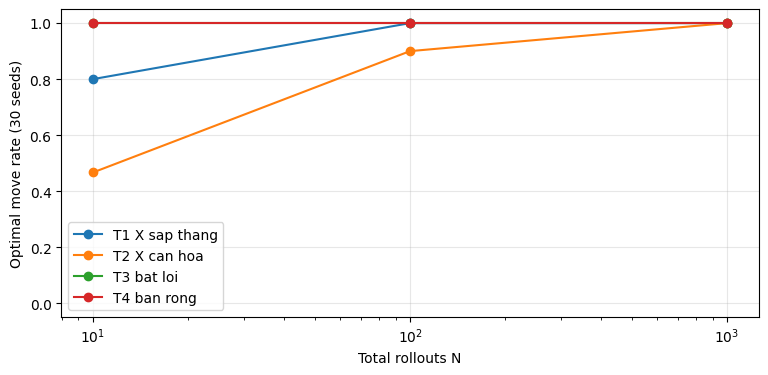

In [4]:
# One warm-up per state and budget, outside the timer.
rows = []
for state, board in STATES.items():
    optimal_value, optimal = optimal_moves(board)
    for budget in BUDGETS:
        monte_carlo_search(board, budget, seed=SEED)
        measurements = [monte_carlo_search(board, budget, seed=seed) for seed in range(REPEATS)]
        counts = Counter(item['move'] for item in measurements)
        mode, frequency = counts.most_common(1)[0]
        rows.append({'state': state, 'N': budget, 'modal_move': mode,
                     'modal_rate': frequency / REPEATS,
                     'optimal_rate': sum(item['move'] in optimal for item in measurements) / REPEATS,
                     'mean_ms': 1000 * np.mean([item['elapsed_s'] for item in measurements]),
                     'move_counts': str(dict(sorted(counts.items())))})
stability = pd.DataFrame(rows)
display(stability)
fig, ax = plt.subplots(figsize=(9, 4))
for label, group in stability.groupby('state', sort=False):
    ax.plot(group['N'], group['optimal_rate'], marker='o', label=label)
ax.set(xscale='log', ylim=(-0.05, 1.05), xlabel='Total rollouts N', ylabel='Optimal move rate (30 seeds)')
ax.legend(); ax.grid(alpha=.3); plt.show()

### Nhận xét

Đồ thị dùng tỷ lệ tối ưu để phân biệt chất lượng với sự tập trung vào một nước. Ở T1 có nhiều nước thắng tối ưu; modal rate thấp không tự động là kém. T3 thua khi đối thủ tối ưu ở mọi nước, nên optimal rate ở T3 không thể hiện sức phòng thủ. Ở T4 mọi nước mở đầu đều có giá trị hòa khi hai bên chơi tối ưu, nên optimal rate cũng không phân biệt ưu thế trước Random. Phần nhận xét số liệu phía dưới ghi kết quả thực tế.

## Thi đấu với Random

Mỗi cấu hình bắt buộc N=10,100 chạy 100 ván ở từng vai. Thắng/hòa/thua tính từ góc nhìn agent; seed riêng cho agent và đối thủ. PMCS-1000 chỉ đo bộ trạng thái, không mở rộng giải đấu tùy chọn.

In [5]:
def play_vs_random(budget, role, n_games=100, seed=42):
    # Opponent has a separate stream; both roles use the same protocol.
    agent_rng, random_rng = np.random.default_rng(seed), np.random.default_rng(seed + 10000)
    counts = {'wins': 0, 'draws': 0, 'losses': 0}
    moves, elapsed = 0, 0.0
    monte_carlo_search(empty_board(), budget, player=role, seed=seed)  # warm-up
    for _ in range(n_games):
        board, player = empty_board(), 'x'
        while utility(board, role) is None:
            if player == role:
                start = perf_counter()
                action = monte_carlo_search(board, budget, player, int(agent_rng.integers(2**63)))['move']
                elapsed += perf_counter() - start
                moves += 1
            else:
                action = int(random_rng.choice(actions(board)))
            board = result(board, player, action)
            player = other(player)
        score = utility(board, role)
        counts[{1:'wins', 0:'draws', -1:'losses'}[score]] += 1
    assert sum(counts.values()) == n_games
    return {'agent': f'{ALGORITHM}-{budget}', 'role': role, **counts,
            'agent_moves': moves, 'total_agent_s': elapsed, 'mean_move_ms': 1000 * elapsed / moves}

# Required budgets: 100 games as X and 100 as O per agent.
match_results = pd.DataFrame([play_vs_random(N, role, GAMES_PER_ROLE, SEED)
                              for N in (10, 100) for role in ('x', 'o')])
display(match_results)

,agent,role,wins,draws,losses,agent_moves,total_agent_s,mean_move_ms
0,PMCS-10,x,94,2,4,388,0.435829,1.123271
1,PMCS-10,o,74,8,18,331,0.446073,1.347652
2,PMCS-100,x,97,3,0,340,3.225586,9.487019
3,PMCS-100,o,90,6,4,333,2.695701,8.095199


### Nhận xét và kết quả bàn giao

Tăng ngân sách thường tăng thời gian; random rollout đánh giá đối thủ ngẫu nhiên nên không bảo đảm tránh bẫy của đối thủ tối ưu. So sánh hai vai riêng vì lợi thế đi trước. Không suy ra thuật toán mạnh nhất chỉ từ vài fixture hoặc các trận với Random.

In [6]:
lines = []
for state, group in stability.groupby('state', sort=False):
    low, high = group.iloc[0], group.iloc[-1]
    lines.append(f"- {state}: optimal rate {low.optimal_rate:.1%} -> {high.optimal_rate:.1%}; "
                 f"modal rate {low.modal_rate:.1%} -> {high.modal_rate:.1%}; "
                 f"mean time {low.mean_ms:.3f} -> {high.mean_ms:.3f} ms.")
for row in match_results.itertuples():
    lines.append(f'- {row.agent} ({row.role}): W/D/L={row.wins}/{row.draws}/{row.losses}, '
                 f'{row.mean_move_ms:.3f} ms per agent move.')
comment = '\n'.join(lines)
display(Markdown(comment))
record_section(ALGORITHM, f'## Tic-Tac-Toe — {ALGORITHM}\n\n'
    'Seed 42; stability seeds 0..29; 100 games per role; warm-up excluded. '
    'Time = sum of agent decision time / number of agent moves; rendering excluded. '
    'N is the TOTAL simulation budget, not N per action.\n\n'
    + markdown_table(stability) + '\n\n' + markdown_table(match_results) + '\n\n' + comment
    + '\n\nModal frequency is stability, not correctness. Multiple optimal moves can reduce modal frequency. '
    'Optimal rate is checked against exact minimax; expected utility against random play does not guarantee minimax play. '
    'T3 has minimax value -1 for all legal moves, so its optimal rate alone is uninformative. '
    'These finite trials do not establish monotonic improvement or universal superiority.\n')

- T1 X sap thang: optimal rate 80.0% -> 100.0%; modal rate 33.3% -> 100.0%; mean time 0.768 -> 54.241 ms.
- T2 X can hoa: optimal rate 46.7% -> 100.0%; modal rate 46.7% -> 100.0%; mean time 0.797 -> 64.583 ms.
- T3 bat loi: optimal rate 100.0% -> 100.0%; modal rate 33.3% -> 100.0%; mean time 1.071 -> 65.800 ms.
- T4 ban rong: optimal rate 100.0% -> 100.0%; modal rate 23.3% -> 86.7%; mean time 3.165 -> 154.297 ms.
- PMCS-10 (x): W/D/L=94/2/4, 1.123 ms per agent move.
- PMCS-10 (o): W/D/L=74/8/18, 1.348 ms per agent move.
- PMCS-100 (x): W/D/L=97/3/0, 9.487 ms per agent move.
- PMCS-100 (o): W/D/L=90/6/4, 8.095 ms per agent move.